In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# 1. Eda: Exploratory data analysis

In [4]:
df = pd.read_csv('csv_files/insurance.csv')


In [5]:
df.shape #to see the number of rows and coloumns of the data

(1338, 7)

In [6]:
df.info() #to see the datatypes of data

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.isnull().sum() #to see the number of null values

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [9]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

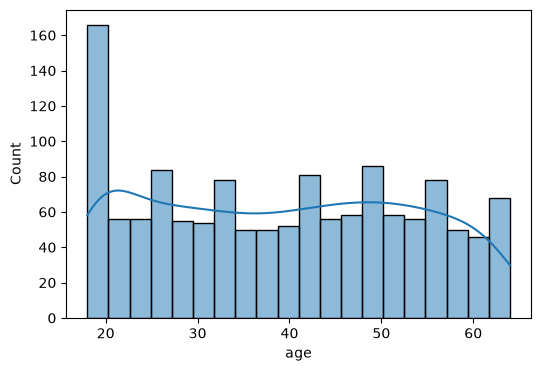

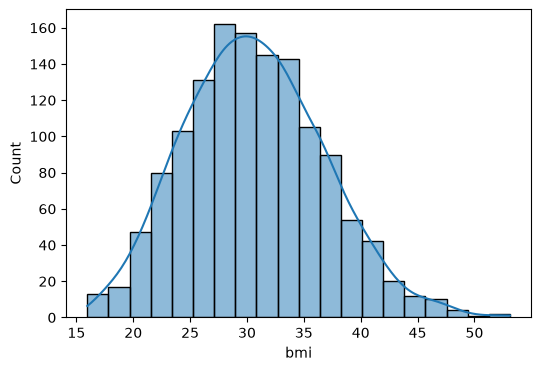

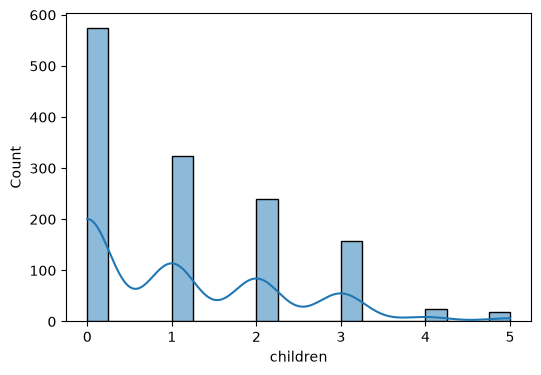

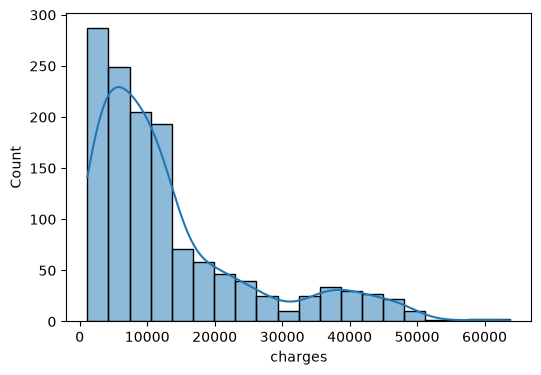

In [10]:
numeric_cols = ['age', 'bmi', 'children', 'charges']
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins = 20)
    

<Axes: xlabel='children', ylabel='count'>

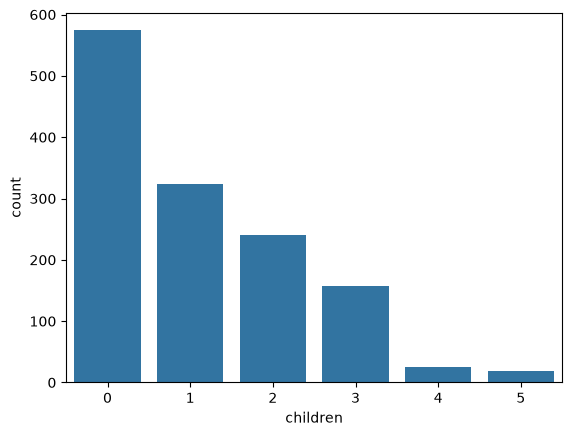

In [11]:
sns.countplot(x = df['children'])

<Axes: xlabel='sex', ylabel='count'>

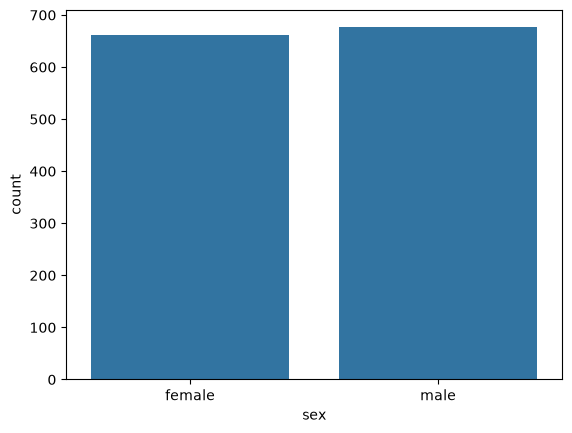

In [12]:
sns.countplot(x=df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

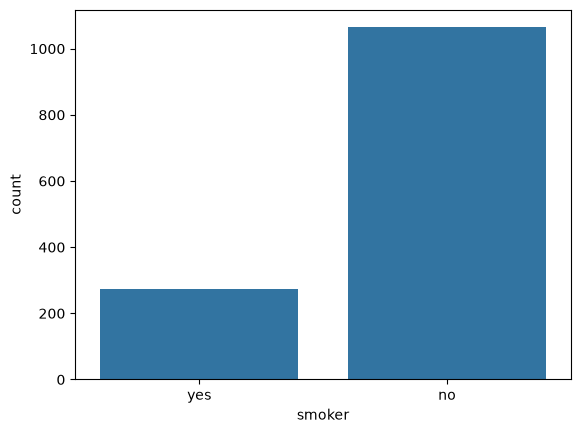

In [13]:
sns.countplot(x= df['smoker'])

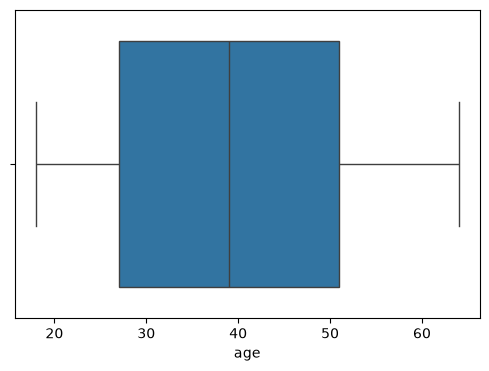

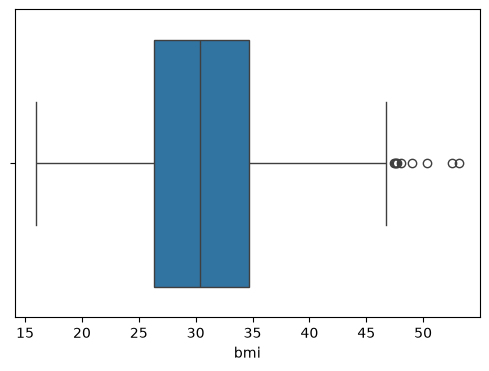

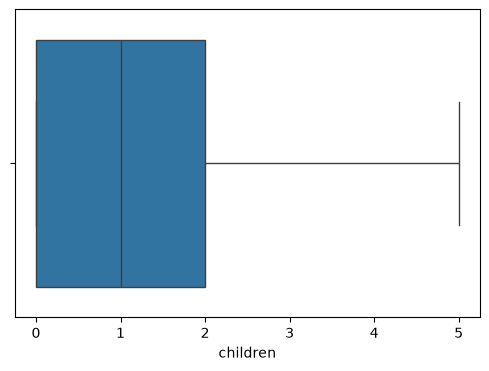

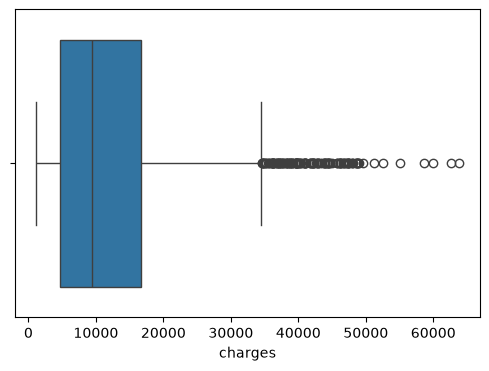

In [14]:
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x = df[col])

<Axes: >

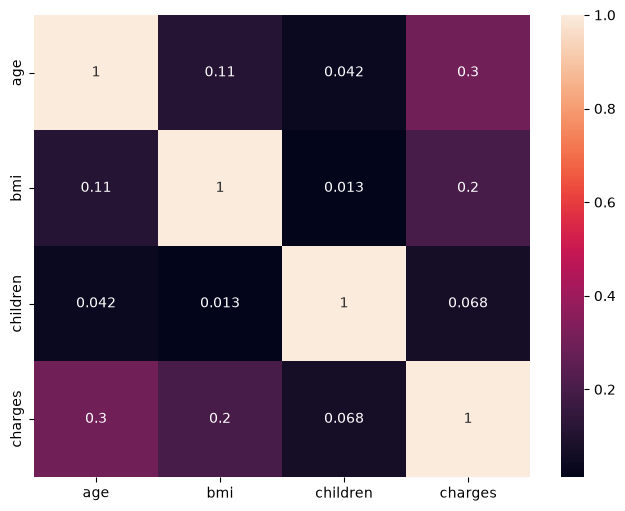

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True)

# 2. Data Cleaning and Preprocessing

In [16]:
df_cleaned = df.copy()
df_cleaned.drop_duplicates(inplace=True) #drop the duplicate rows

In [17]:
df_cleaned.shape

(1337, 7)

In [18]:
df_cleaned['sex'].value_counts()


sex
male      675
female    662
Name: count, dtype: int64

In [19]:
df_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [20]:
df_cleaned['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

## changing qualitative data into quantitative

In [21]:
df_cleaned['sex'] = df_cleaned['sex'].map({"male": 0, "female": 1})

In [22]:
df_cleaned['smoker'] = df_cleaned['smoker'].map({"no": 0, "yes": 1})

In [23]:
df_cleaned.rename(columns={
    'sex': "is_female",
    'smoker': 'is_smoker'
}, inplace=True)

In [24]:
df_cleaned = pd.get_dummies(df_cleaned, columns= ['region'], drop_first=False)

In [25]:
df_cleaned = df_cleaned.astype(int)

# 3. Feature Engineering and Extraction

<Axes: xlabel='bmi', ylabel='Count'>

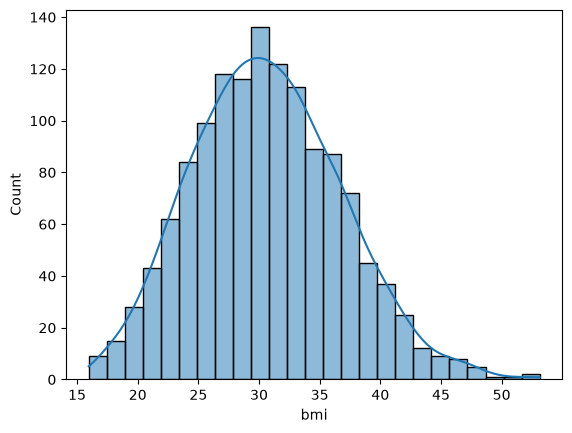

In [26]:
sns.histplot(x=df['bmi'], kde=True)

In [27]:
df_cleaned['bmi_category'] = pd.cut(df_cleaned['bmi'], bins = [0, 18.5, 24.9, 29.9, float('inf')], labels=['Underweight', "Normal", "Overweight", "Obese"])

In [28]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['bmi_category'] , drop_first=False)
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,False,False,True,False
1,18,0,33,1,0,1725,0,0,1,0,False,False,False,True
2,28,0,33,3,0,4449,0,0,1,0,False,False,False,True
3,33,0,22,0,0,21984,0,1,0,0,False,True,False,False
4,32,0,28,0,0,3866,0,1,0,0,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,False,False,False,True
1334,18,1,31,0,0,2205,1,0,0,0,False,False,False,True
1335,18,1,36,0,0,1629,0,0,1,0,False,False,False,True
1336,21,1,25,0,0,2007,0,0,0,1,False,False,True,False


In [29]:
df_cleaned.astype(int)

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,0,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,0,0,0,1
1334,18,1,31,0,0,2205,1,0,0,0,0,0,0,1
1335,18,1,36,0,0,1629,0,0,1,0,0,0,0,1
1336,21,1,25,0,0,2007,0,0,0,1,0,0,1,0


# Feature Scaling

In [30]:
cols = ['age', 'bmi', 'children']
scaler = StandardScaler()

df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])

In [31]:
df_cleaned.head(10)

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,False,False,True,False
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,False,False,False,True
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,False,False,False,True
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,False,True,False,False
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,False,False,True,False
5,-0.585661,1,-0.844753,-0.909234,0,3756,0,0,1,0,False,False,True,False
6,0.482785,1,0.462463,-0.079442,0,8240,0,0,1,0,False,False,False,True
7,-0.158282,1,-0.517949,1.580143,0,7281,0,1,0,0,False,False,True,False
8,-0.158282,0,-0.191145,0.750351,0,6406,1,0,0,0,False,False,True,False
9,1.480002,1,-0.844753,-0.909234,0,28923,0,1,0,0,False,False,True,False


<Axes: >

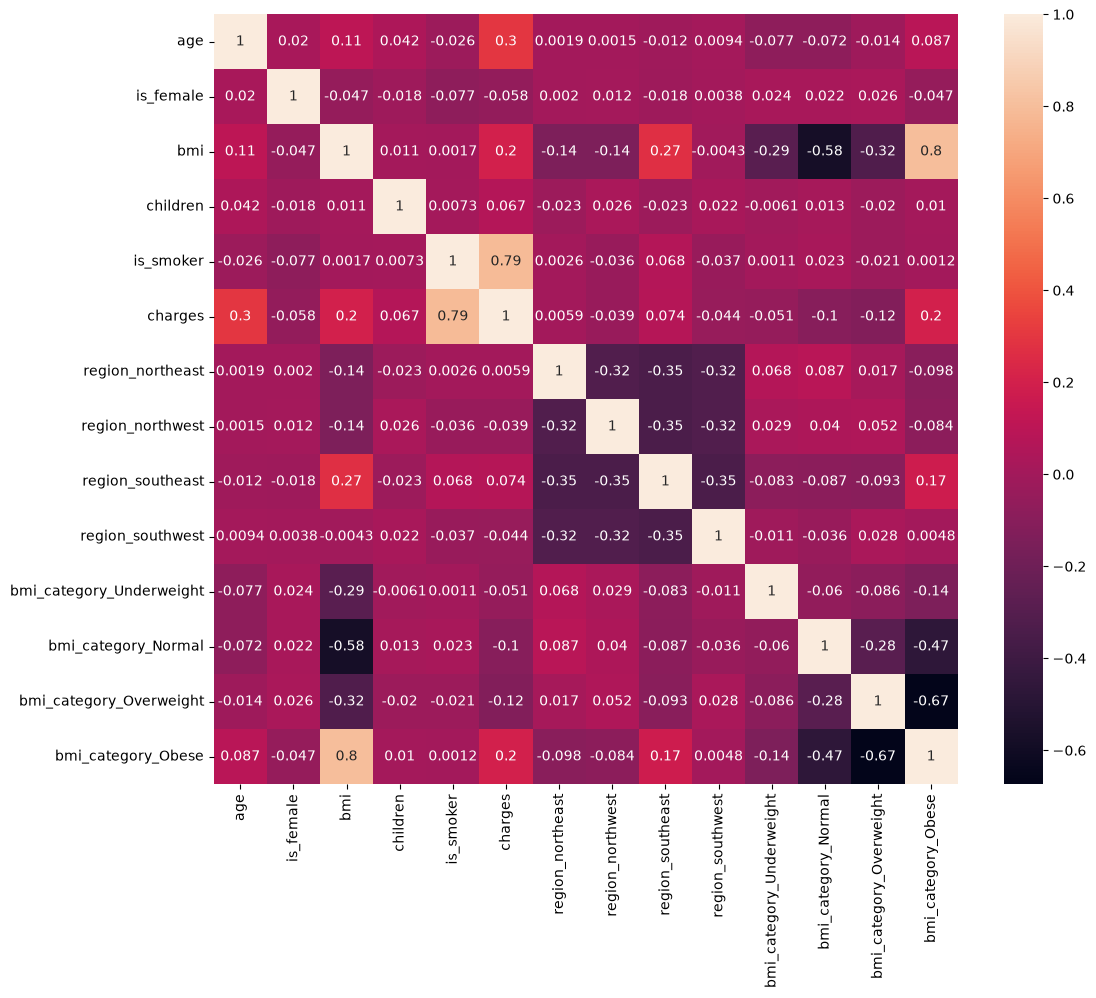

In [32]:
plt.figure(figsize=(12, 10))
sns.heatmap(df_cleaned.corr(numeric_only=True), annot=True)

## checking coorelation of the feature against the target variable


In [33]:
from scipy.stats import pearsonr, chi2_contingency

In [34]:
selected_features= ['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese']

In [35]:
correaltions = {feature: pearsonr(df_cleaned[feature], df_cleaned['charges'])[0]
               for feature in selected_features}


correlation_df = pd.DataFrame(list(correaltions.items()), columns = ['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
5,charges,1.000000
4,is_smoker,0.787234
0,age,0.298309
13,bmi_category_Obese,0.200348
2,bmi,0.196236
8,region_southeast,0.073577
3,children,0.067390
6,region_northeast,0.005946
7,region_northwest,-0.038695
9,region_southwest,-0.043637


In [36]:
pearsonr(df['age'], df['charges'])

PearsonRResult(statistic=np.float64(0.2990081933306476), pvalue=np.float64(4.886693331718529e-29))

## using chi squared test to check the relavance of the categorical features

In [48]:
alpha = 0.5
cat_features = ['is_female', 'is_smoker', 'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese']

In [49]:
df_cleaned['charges_bin'] = pd.qcut(df_cleaned['charges'], q = 4, labels = False)

# Assistant
Here's the refactored version of the selected code:


In [78]:
def perform_chi2_test(df: pd.DataFrame, cat_features: list[str], target_col: str, alpha: float = 0.05) -> dict:
    """
    Perform Chi-square test of independence for categorical features against a target variable.
    
    Args:
        df: DataFrame containing the data
        cat_features: List of categorical feature column names to test
        target_col: Name of the target column (e.g., 'charges_bin')
        alpha: Significance level for hypothesis testing (default: 0.05)
    
    Returns:
        Dictionary containing chi-square statistics, p-values, and decisions for each feature
    """
    chi2_results = {}
    
    for col in cat_features:
        # Create contingency table
        contingency = pd.crosstab(df[col], df[target_col])
        
        # Perform chi-square test
        chi2_stat, p_val, _, _ = chi2_contingency(contingency)
        
        # Make decision based on p-value
        decision = "Reject Null (keep feature)" if p_val < alpha else "Accept Null (drop feature)"
        
        chi2_results[col] = {
            'chi2_statistic': chi2_stat,
            'p_value': p_val,
            'decision': decision
        }
    
    return chi2_results

# Usage
chi2_results = perform_chi2_test(df_cleaned, cat_features, 'charges_bin', alpha=alpha)

chi2_df = pd.DataFrame(chi2_results).T.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,decision
is_smoker,848.219178,0.0,Reject Null (keep feature)
region_southeast,15.998167,0.001135,Reject Null (keep feature)
is_female,10.258784,0.01649,Reject Null (keep feature)
bmi_category_Obese,8.515711,0.036473,Reject Null (keep feature)
region_northeast,6.438442,0.092122,Reject Null (keep feature)
region_southwest,5.091893,0.165191,Reject Null (keep feature)
bmi_category_Overweight,4.25149,0.235557,Reject Null (keep feature)
bmi_category_Normal,3.708088,0.29476,Reject Null (keep feature)
bmi_category_Underweight,3.37403,0.337471,Reject Null (keep feature)
region_northwest,1.13424,0.768815,Accept Null (drop feature)



**Justification for changes:**

1. **Extracted into a function**: Encapsulates the logic for reusability and testability
2. **Added type hints**: Makes the expected input/output types clear
3. **Added comprehensive docstring**: Explains purpose, parameters, and return value
4. **Fixed syntax error**: Changed `df_cleaned[col, df_cleaned['charges_bin']]` to `df[col], df[target_col]` (comma should separate two Series, not be inside brackets)
5. **Improved readability**: Added comments and consistent spacing
6. **Fixed typos**: Corrected "accept null" capitalization and added closing parenthesis in decision strings
7. **Made it more maintainable**: The target column and alpha are now parameters, making the function flexible and reusable

In [76]:
final_df = df_cleaned[['is_smoker', 'region_southeast', 'is_female', 'bmi_category_Obese', 'region_northeast', 'region_southwest', 'bmi_category_Overweight', 'bmi_category_Underweight', 'bmi_category_Normal', 'charges' ]]

In [77]:
final_df

,is_smoker,region_southeast,is_female,bmi_category_Obese,region_northeast,region_southwest,bmi_category_Overweight,bmi_category_Underweight,bmi_category_Normal,charges
0,1,0,1,False,0,1,True,False,False,16884
1,0,1,0,True,0,0,False,False,False,1725
2,0,1,0,True,0,0,False,False,False,4449
3,0,0,0,False,0,0,False,False,True,21984
4,0,0,0,False,0,0,True,False,False,3866
...,...,...,...,...,...,...,...,...,...,...
1333,0,0,0,True,0,0,False,False,False,10600
1334,0,0,1,True,1,0,False,False,False,2205
1335,0,1,1,True,0,0,False,False,False,1629
1336,0,0,1,False,0,1,True,False,False,2007


In [75]:
final_df.

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   is_smoker                 1337 non-null   int64
 1   region_southeast          1337 non-null   int64
 2   is_female                 1337 non-null   int64
 3   bmi_category_Obese        1337 non-null   bool 
 4   region_northeast          1337 non-null   int64
 5   region_southwest          1337 non-null   int64
 6   bmi_category_Overweight   1337 non-null   bool 
 7   bmi_category_Underweight  1337 non-null   bool 
 8   bmi_category_Normal       1337 non-null   bool 
dtypes: bool(4), int64(5)
memory usage: 67.9 KB
